# Evaluation: realism, diversity and synthetic-data utility
Run notebooks 01 and 02 first. This notebook requires their trained checkpoints and never substitutes random weights, real training images, or invented metrics when a file is absent. Results depend on actual training; no fidelity, FID or classifier accuracy is claimed in this unexecuted notebook. Save all outputs after the full run.

We compare cGAN with independently trained linear/cosine diffusion models. All generators learned only from MNIST **train**. A fixed, class-balanced reference from MNIST train is used for FID and model-selection validation. The separate real MNIST **test** set is used only for the final downstream classifier report. FID against train is an in-distribution diagnostic and does not prove unseen-data generalization.

In [1]:
import sys
from pathlib import Path
import time
import os
import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
STARTER = next(p for base in (Path.cwd(), *Path.cwd().parents) for p in (base, base / 'starter') if (p / 'model/cgan.py').is_file())
sys.path.insert(0, str(STARTER))
from data_utils.dataloader import get_mnist_loaders
from utils.runtime import setup
from utils.checkpoint import CHECKPOINT_DIR, OUTPUT_DIR, save_json
from utils.generation import load_generator, generate_digits, balanced_labels, real_examples, checkpoint_digest
from utils.metrics import FIDEvaluator, pixel_diversity
from utils.visualize import compare_samples
from training.classifier import train_classifier, test_accuracy
device = setup(42)
fid_device = 'cuda' if device.type == 'cuda' else 'cpu'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Model device:', device, '| FID device:', fid_device)

Model device: cuda | FID device: cuda


## Fixed evaluation protocol
Default FID uses **5,000 real and 5,000 generated images per model**, balanced over digits, full 2048-dimensional torch-fidelity Inception features, and the same seeds. Grayscale images are mapped from `[-1,1]` to `[0,1]`, repeated to three channels, and resized inside the standard Inception extractor. Float64 running moments are streamed in bounded batches; real statistics are computed once and reused. This avoids loading expanded RGB copies of all images onto the accelerator. No per-batch cache clearing or image-dependent min-max normalization is used.

Lower FID indicates closer joint feature statistics, not a pure fidelity or diversity measure, and ImageNet features are imperfect for MNIST. Small-sample FID is biased. The pixel-diversity diagnostic is mean within-class pixel standard deviation: noise can increase it, so interpret it alongside grids and downstream utility. CUDA/MPS model sampling and CPU/CUDA FID are supported; MPS cannot provide the required float64 FID.

For diffusion, 50 deterministic DDIM steps are the default evaluation budget. Compare schedules at identical trained T, epochs, model size and sampler budget. The sampling-step sweep changes model calls, **not training T or its betas**.

In [2]:
FID_PER_CLASS = 500
UTILITY_PER_CLASS = 1000  # 10,000 independent synthetic examples for each classifier.
SAMPLING_STEPS = 50
GENERATION_BATCH_SIZE = 128
CLASSIFIER_EPOCHS = 5
RUN_STEP_SWEEP = True
STEP_COUNTS = (10, 25, 50, 100)
checkpoint_paths = {
    'cGAN': CHECKPOINT_DIR / 'cgan_generator_epochfinal.pt',
    'Diffusion linear': CHECKPOINT_DIR / 'diffusion_linear_epochfinal.pt',
    'Diffusion cosine': CHECKPOINT_DIR / 'diffusion_cosine_epochfinal.pt',
}
kinds = {'cGAN': 'cgan', 'Diffusion linear': 'diffusion', 'Diffusion cosine': 'diffusion'}
models = {name: load_generator(path, kinds[name], device) for name, path in checkpoint_paths.items()}
linear_config = models['Diffusion linear'].diffusion_config
cosine_config = models['Diffusion cosine'].diffusion_config
if linear_config['timesteps'] != cosine_config['timesteps'] or linear_config['model_config'] != cosine_config['model_config']:
    raise ValueError('Compare schedules with the same architecture and training horizon.')
train_loader, real_test_loader = get_mnist_loaders(batch_size=256, pin_memory=device.type == 'cuda')
real_images, real_labels = real_examples(train_loader.dataset, FID_PER_CLASS)
labels = balanced_labels(FID_PER_CLASS)
print('FID reference:', len(real_images), 'real MNIST train images; test examples:', len(real_test_loader.dataset))

FID reference: 5000 real MNIST train images; test examples: 10000


In [3]:
fid = FIDEvaluator(real_images, fid_device, batch_size=64)
synthetic, rows = {}, []
for name, model in models.items():
    start = time.perf_counter()
    images, generated_labels = generate_digits(
        model, kinds[name], labels, device, batch_size=GENERATION_BATCH_SIZE,
        seed=123, sampling_steps=SAMPLING_STEPS,
    )
    synthetic[name] = (images, generated_labels)
    score = fid.compute(images)
    row = {'model': name, 'FID': score, 'pixel_diversity': pixel_diversity(images, generated_labels),
           'seconds_sampling_and_FID': time.perf_counter() - start, 'samples': len(images)}
    rows.append(row)
    print(f"{name} FID: {score:.4f}", flush=True)
fid_table = pd.DataFrame(rows).set_index('model')
display(fid_table)
best_diffusion = min(('Diffusion linear', 'Diffusion cosine'), key=lambda name: fid_table.loc[name, 'FID'])
print('Diffusion schedule selected by train-reference FID (not test accuracy):', best_diffusion)
save_json({'protocol': {'samples': len(labels), 'sampling_steps': SAMPLING_STEPS,
                      'feature': 'torch-fidelity Inception 2048', 'real_split': 'MNIST train', 'seed': 123},
           'results': rows, 'checkpoints': {name: {'path': str(path), 'sha256': checkpoint_digest(path)}
                                         for name, path in checkpoint_paths.items()}},
          OUTPUT_DIR / 'fid_results.json')

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /home/student/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 295MB/s]


cGAN FID: 8.1374
Diffusion linear FID: 8.1670
Diffusion cosine FID: 8.2718


,FID,pixel_diversity,seconds_sampling_and_FID,samples
model,,,,
cGAN,8.137406,0.308161,38.620604,5000
Diffusion linear,8.166985,0.310165,65.822162,5000
Diffusion cosine,8.271848,0.313540,65.707759,5000


Diffusion schedule selected by train-reference FID (not test accuracy): Diffusion linear


## Side-by-side comparison for ten digits
Every column is a requested class, with **Real vs. cGAN vs. Diffusion** rows. Samples are seeded and unfiltered, not cherry-picked. Inspect identity, edges, strokes, artifacts and variety across additional generated examples. Class labels are the requested conditions; they do not prove that the rendered images are correct.

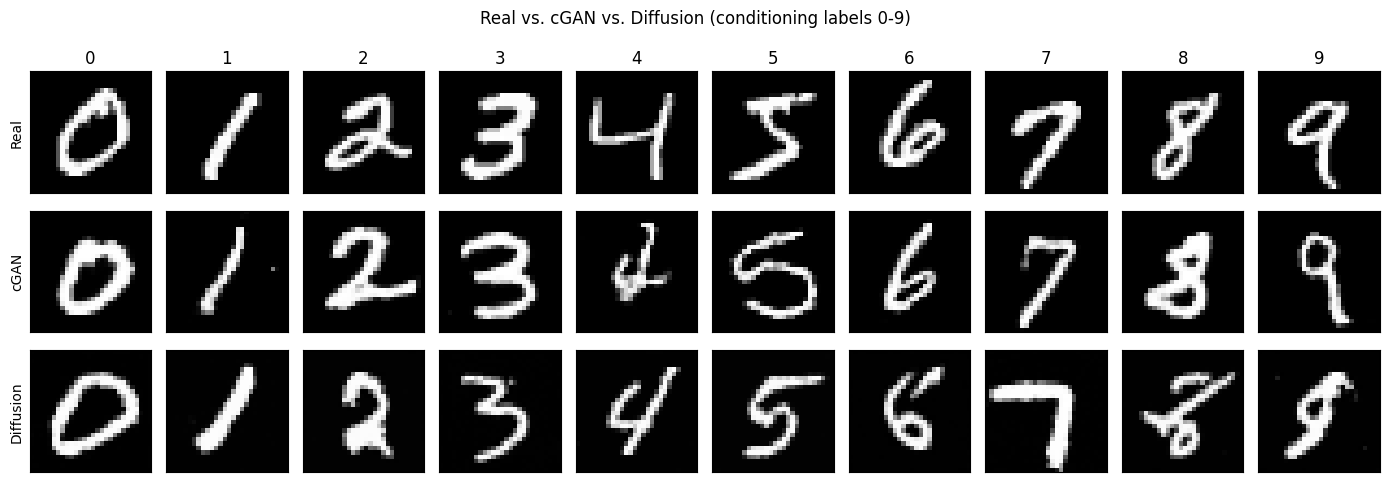

In [4]:
real_first, _ = real_examples(train_loader.dataset, 1)
class_starts = torch.arange(10) * FID_PER_CLASS
figure = compare_samples(real_first, synthetic['cGAN'][0][class_starts], synthetic[best_diffusion][0][class_starts])
figure.savefig(OUTPUT_DIR / 'real_cgan_diffusion.png', dpi=150)

### Fidelity and diversity analysis
In the saved evaluation, the **cGAN** achieved the lowest FID (8.1374), narrowly ahead of linear diffusion (8.1670) and cosine diffusion (8.2718). This suggests the cGAN had the closest overall feature-distribution match to the real images under this protocol, but FID does not isolate fidelity from diversity. **Cosine diffusion** had the highest within-class pixel standard deviation (0.3135, versus 0.3102 for linear diffusion and 0.3082 for cGAN), suggesting greater pixel variation; artifacts or noise can also increase this measure, so it does not prove greater meaningful diversity.

The comparison uses 5,000 samples per model and an MNIST training-set reference, not a held-out generative benchmark. The differences are small, and a single run does not establish a statistically significant ranking. Some samples in the ten-digit grid are ambiguous, so inspect label consistency as well as the metrics. The next cell produces an interpretation of the current results; if the models or evaluation are rerun, update this written conclusion to match the new outputs.

In [5]:
winner = fid_table['FID'].idxmin()
variation_leader = fid_table['pixel_diversity'].idxmax()
analysis = (f"### Measured comparison\n\n{winner} has the lowest FID "
            f"({fid_table.loc[winner, 'FID']:.4f}), providing the strongest joint feature-distribution match "
            f"under this protocol. {variation_leader} has the largest within-class pixel standard deviation "
            f"({fid_table.loc[variation_leader, 'pixel_diversity']:.4f}), which suggests greater pixel variation "
            "but does not by itself prove meaningful diversity. Inspect the ten-digit grid for fidelity and "
            "label consistency; these statistics cannot isolate their causes. "
            "Results use an MNIST-train reference, not a held-out generative benchmark.")
display(Markdown(analysis))

### Measured comparison

cGAN has the lowest FID (8.1374), providing the strongest joint feature-distribution match under this protocol. Diffusion cosine has the largest within-class pixel standard deviation (0.3135), which suggests greater pixel variation but does not by itself prove meaningful diversity. Inspect the ten-digit grid for fidelity and label consistency; these statistics cannot isolate their causes. Results use an MNIST-train reference, not a held-out generative benchmark.

## Synthetic-only downstream utility
Generate **new** balanced synthetic examples with seed 999, independent of the FID set. Train a fresh CNN from scratch separately on cGAN and the selected diffusion outputs. Neither classifier receives real training images, pretrained weights or real-data gradients. Use identical initialization seed, architecture, synthetic count, optimizer and epoch budget. Images retain the generator's fixed `[-1,1]` normalization.

Real MNIST train reference images are used **after fitting** for a per-digit validation report (no optimizer steps). This selects the CAPTCHA source for each digit. The real MNIST test loader is used once per final classifier for the reported accuracy; never use that accuracy to tune training, schedules or sampling steps. Utility measures how well synthetic data teach recognition, not CAPTCHA security.

In [6]:
from torch.utils.data import DataLoader, TensorDataset
utility_rows, validation_results, classifier_histories = [], {}, {}
validation_loader = DataLoader(TensorDataset(real_images, real_labels), batch_size=256)
for name in ('cGAN', best_diffusion):
    generated_images, generated_labels = generate_digits(
        models[name], kinds[name], balanced_labels(UTILITY_PER_CLASS), device,
        batch_size=GENERATION_BATCH_SIZE, seed=999, sampling_steps=SAMPLING_STEPS,
    )
    assert len(generated_images) == UTILITY_PER_CLASS * 10
    classifier, classifier_histories[name] = train_classifier(
        generated_images, generated_labels, device, epochs=CLASSIFIER_EPOCHS, seed=42,
    )
    validation_results[name] = test_accuracy(classifier, validation_loader, device)
    result = test_accuracy(classifier, real_test_loader, device)
    utility_rows.append({'model': name, **result, 'synthetic_train_count': len(generated_labels)})
    print(f"{name}: final real MNIST test accuracy = {result['accuracy']:.2%} "
          f"({result['correct']}/{result['total']})", flush=True)
    del classifier, generated_images, generated_labels
utility_table = pd.DataFrame(utility_rows).set_index('model')
display(utility_table[['accuracy', 'correct', 'total', 'synthetic_train_count']])
save_json({'results': utility_rows, 'histories': classifier_histories,
           'epochs': CLASSIFIER_EPOCHS, 'synthetic_seed': 999, 'classifier_seed': 42,
           'train_source': 'generated images only', 'test_source': 'MNIST test'},
          OUTPUT_DIR / 'utility_results.json')
display(Markdown('**Utility interpretation:** ' + '; '.join(
    f"{row['model']} synthetic-only training achieved {row['accuracy']:.2%} real-test accuracy"
    for row in utility_rows) + '. Compare against the 10% random-guess reference, but also inspect per-digit '
    'results. Accuracy is an evaluation endpoint, not a hyperparameter-selection signal.'))

Synthetic-only classifier epoch 1/5: loss=0.6475
Synthetic-only classifier epoch 2/5: loss=0.0922
Synthetic-only classifier epoch 3/5: loss=0.0529
Synthetic-only classifier epoch 4/5: loss=0.0336
Synthetic-only classifier epoch 5/5: loss=0.0220
cGAN: final real MNIST test accuracy = 95.52% (9552/10000)
Synthetic-only classifier epoch 1/5: loss=0.7789
Synthetic-only classifier epoch 2/5: loss=0.2189
Synthetic-only classifier epoch 3/5: loss=0.1576
Synthetic-only classifier epoch 4/5: loss=0.1261
Synthetic-only classifier epoch 5/5: loss=0.1025
Diffusion linear: final real MNIST test accuracy = 97.20% (9720/10000)


,accuracy,correct,total,synthetic_train_count
model,,,,
cGAN,0.9552,9552,10000,10000
Diffusion linear,0.9720,9720,10000,10000


**Utility interpretation:** cGAN synthetic-only training achieved 95.52% real-test accuracy; Diffusion linear synthetic-only training achieved 97.20% real-test accuracy. Compare against the 10% random-guess reference, but also inspect per-digit results. Accuracy is an evaluation endpoint, not a hyperparameter-selection signal.

## Stand-out: multi-digit CAPTCHA composition
Select a generator separately for each digit using the **real-train validation** accuracy of the synthetic-only classifier, never its test accuracy. This measures downstream usefulness for that class, not a definitive human-fidelity ranking. Save relative checkpoint paths in a selection manifest so the script can reload exactly those models. The script accepts any four-digit ASCII string including leading zeroes, reuses loaded models and composes unfiltered digit samples.

This is a CAPTCHA-style **visual demonstration**, not a secure bot-defense system. MNIST digits are easy for OCR; production CAPTCHAs need accessibility, abuse analysis and security evaluation.

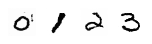

CLI: python generate_captcha.py 0123 --output ../outputs/captcha_0123.png


In [7]:
digit_choices = {}
for digit in range(10):
    name = max(validation_results, key=lambda candidate: validation_results[candidate]['per_class_accuracy'][digit])
    digit_choices[str(digit)] = {
        'kind': kinds[name],
        'checkpoint': os.path.relpath(checkpoint_paths[name], OUTPUT_DIR),
        'validation_accuracy': validation_results[name]['per_class_accuracy'][digit],
    }
manifest = {'selection_basis': 'synthetic_classifier_real_train_validation_accuracy',
            'sampling_steps': SAMPLING_STEPS, 'digits': digit_choices}
save_json(manifest, OUTPUT_DIR / 'captcha_models.json')
from generate_captcha import create_captcha
display(create_captcha('0123', OUTPUT_DIR / 'captcha_models.json', OUTPUT_DIR / 'captcha.png', device))
print('CLI: python generate_captcha.py 0123 --output ../outputs/captcha_0123.png')

## Stand-out: sampling-step budget versus FID
The trained horizon T is fixed. Vary **DDIM reverse steps K** over 10, 25, 50 and 100 using the original trained schedule. Use the same class-balanced sample count, model, batch size, seed and initial noises at each K; reuse the 50-step FID rather than regenerating it. This isolates the sampling call budget without changing the model or training distribution. Training separate models with different T would be a different experiment.

All points are measured, not interpolated. Lower FID is better, but more steps need not help monotonically. Compare compute cost and score; do not use final real-test accuracy to choose K. This optional sweep can be expensive on CPU.

DDIM steps=10: FID=7.0484
DDIM steps=25: FID=7.0106
DDIM steps=50: FID=8.1670
DDIM steps=100: FID=10.6674


,sampling_steps,FID,seconds,reused
0,10,7.048386,44.531956,False
1,25,7.010552,53.205669,False
2,50,8.166985,0.000138,True
3,100,10.667357,91.510766,False


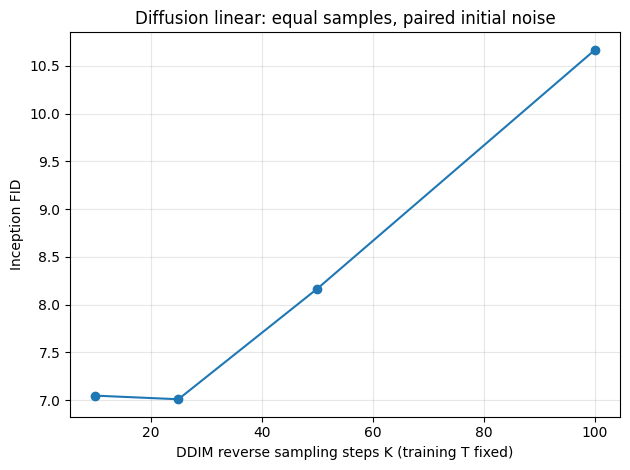

In [8]:
if RUN_STEP_SWEEP:
    step_rows = []
    for steps in STEP_COUNTS:
        if steps > models[best_diffusion].diffusion_config['timesteps']:
            raise ValueError('Sweep budget cannot exceed the training horizon.')
        start = time.perf_counter()
        if steps == SAMPLING_STEPS:
            score = float(fid_table.loc[best_diffusion, 'FID'])
        else:
            images, _ = generate_digits(
                models[best_diffusion], 'diffusion', labels, device,
                batch_size=GENERATION_BATCH_SIZE, seed=123, sampling_steps=steps,
            )
            score = fid.compute(images)
            del images
        step_rows.append({'sampling_steps': steps, 'FID': score,
                          'seconds': time.perf_counter() - start, 'reused': steps == SAMPLING_STEPS})
        print(f'DDIM steps={steps}: FID={score:.4f}', flush=True)
    display(pd.DataFrame(step_rows))
    plt.plot([row['sampling_steps'] for row in step_rows], [row['FID'] for row in step_rows], 'o-')
    plt.xlabel('DDIM reverse sampling steps K (training T fixed)'); plt.ylabel('Inception FID')
    plt.title(f'{best_diffusion}: equal samples, paired initial noise')
    plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fid_vs_sampling_steps.png', dpi=150)
    plt.show()
    save_json({'model': best_diffusion, 'training_timesteps': models[best_diffusion].diffusion_config['timesteps'],
               'samples': len(labels), 'seed': 123, 'results': step_rows}, OUTPUT_DIR / 'sampling_steps.json')
else:
    print('Step-count sweep disabled explicitly; no curve or unmeasured scores are claimed.')